

Objectif :

Le modèle produit des probabilités de prédiction.

Par défaut, la classe ayant la probabilité maximale est sélectionnée.

Nous allons tester plusieurs seuils afin d'améliorer la qualité des signaux BUY et SELL.

In [1]:
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
FINAL_PATH = Path("../data/final")

df = pd.read_csv(
    FINAL_PATH / "BTCUSD_final_dataset.csv"
)

X = df.drop(columns=["target"])
y = df["target"]

split = int(len(df) * 0.8)

X_test = X.iloc[split:]
y_test = y.iloc[split:]

In [3]:
best_model = joblib.load(
    "../models/gradient_boosting_final.pkl"
)

scaler = joblib.load(
    "../models/scaler_final.pkl"
)

X_test_scaled = scaler.transform(X_test)

In [4]:
y_proba = best_model.predict_proba(X_test_scaled)

classes = best_model.classes_
print("Classes :", classes)

idx_sell = list(classes).index(-1)
idx_hold = list(classes).index(0)
idx_buy = list(classes).index(1)

Classes : [-1  0  1]


In [5]:
def predict_with_threshold(y_proba, buy_th=0.35, sell_th=0.35):
    
    y_pred = []
    
    for proba in y_proba:
        
        if proba[idx_buy] >= buy_th:
            y_pred.append(1)
            
        elif proba[idx_sell] >= sell_th:
            y_pred.append(-1)
            
        else:
            y_pred.append(0)
            
    return np.array(y_pred)

In [6]:
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50]

results = []

for th in thresholds:
    
    y_pred_th = predict_with_threshold(
        y_proba,
        buy_th=th,
        sell_th=th
    )
    
    report = classification_report(
        y_test,
        y_pred_th,
        output_dict=True,
        zero_division=0
    )
    
    results.append({
        "threshold": th,
        "precision_buy": report["1"]["precision"],
        "recall_buy": report["1"]["recall"],
        "f1_buy": report["1"]["f1-score"],
        "precision_sell": report["-1"]["precision"],
        "recall_sell": report["-1"]["recall"],
        "f1_sell": report["-1"]["f1-score"],
        "f1_macro": report["macro avg"]["f1-score"],
        "accuracy": report["accuracy"]
    })
    
    print(f"\n===== Threshold : {th} =====")
    print(confusion_matrix(y_test, y_pred_th))
    print(classification_report(y_test, y_pred_th, zero_division=0))


===== Threshold : 0.3 =====
[[120  29 111]
 [208  62 146]
 [166  32 121]]
              precision    recall  f1-score   support

          -1       0.24      0.46      0.32       260
           0       0.50      0.15      0.23       416
           1       0.32      0.38      0.35       319

    accuracy                           0.30       995
   macro avg       0.36      0.33      0.30       995
weighted avg       0.38      0.30      0.29       995


===== Threshold : 0.35 =====
[[124  66  70]
 [173 156  87]
 [142 100  77]]
              precision    recall  f1-score   support

          -1       0.28      0.48      0.35       260
           0       0.48      0.38      0.42       416
           1       0.33      0.24      0.28       319

    accuracy                           0.36       995
   macro avg       0.37      0.36      0.35       995
weighted avg       0.38      0.36      0.36       995


===== Threshold : 0.4 =====
[[105 121  34]
 [138 235  43]
 [121 162  36]]
            

In [7]:
threshold_results = pd.DataFrame(results)
threshold_results

,threshold,precision_buy,recall_buy,f1_buy,precision_sell,recall_sell,f1_sell,f1_macro,accuracy
0,0.30,0.320106,0.379310,0.347202,0.242915,0.461538,0.318302,0.298520,0.304523
1,0.35,0.329060,0.241379,0.278481,0.282460,0.476923,0.354793,0.352013,0.358794
2,0.40,0.318584,0.112853,0.166667,0.288462,0.403846,0.336538,0.335472,0.377889
3,0.45,0.311475,0.059561,0.100000,0.288136,0.261538,0.274194,0.304863,0.389950
4,0.50,0.355556,0.050157,0.087912,0.285714,0.169231,0.212560,0.292127,0.411055


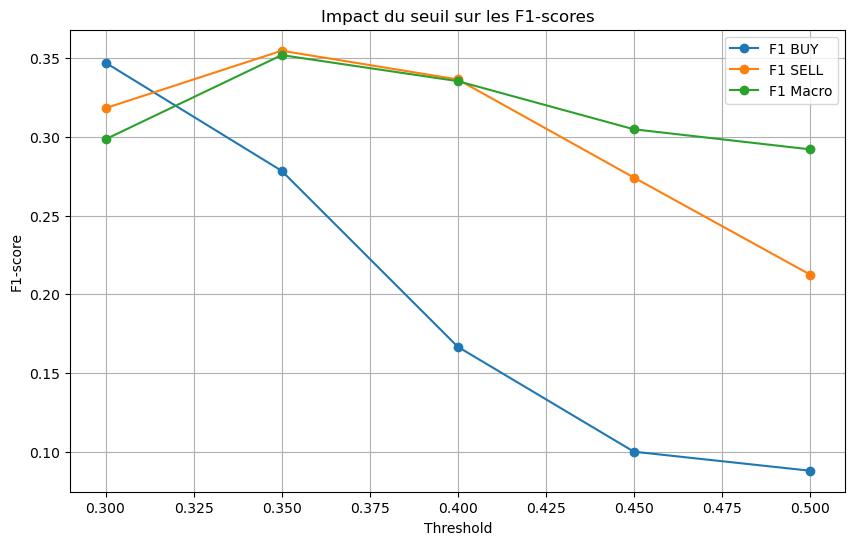

In [8]:
plt.figure(figsize=(10, 6))

plt.plot(threshold_results["threshold"], threshold_results["f1_buy"], marker="o", label="F1 BUY")
plt.plot(threshold_results["threshold"], threshold_results["f1_sell"], marker="o", label="F1 SELL")
plt.plot(threshold_results["threshold"], threshold_results["f1_macro"], marker="o", label="F1 Macro")

plt.title("Impact du seuil sur les F1-scores")
plt.xlabel("Threshold")
plt.ylabel("F1-score")
plt.legend()
plt.grid(True)
plt.show()

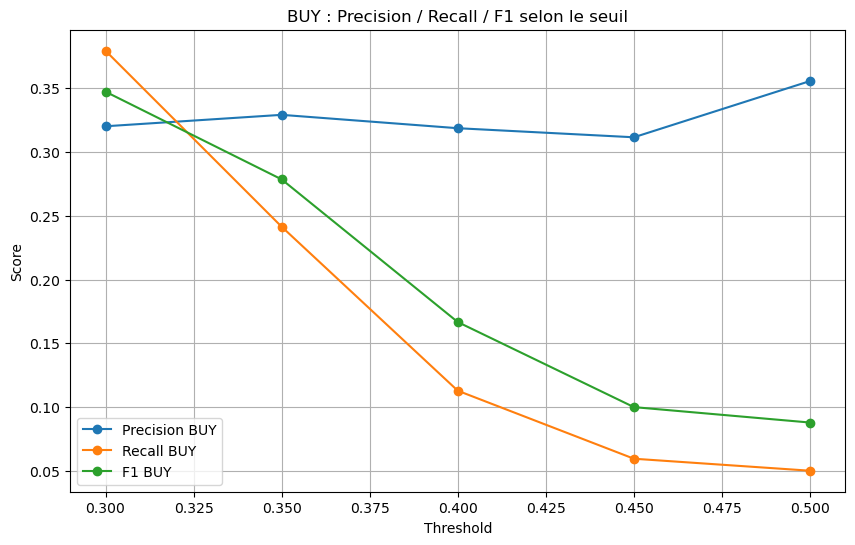

In [9]:
plt.figure(figsize=(10, 6))

plt.plot(threshold_results["threshold"], threshold_results["precision_buy"], marker="o", label="Precision BUY")
plt.plot(threshold_results["threshold"], threshold_results["recall_buy"], marker="o", label="Recall BUY")
plt.plot(threshold_results["threshold"], threshold_results["f1_buy"], marker="o", label="F1 BUY")

plt.title("BUY : Precision / Recall / F1 selon le seuil")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

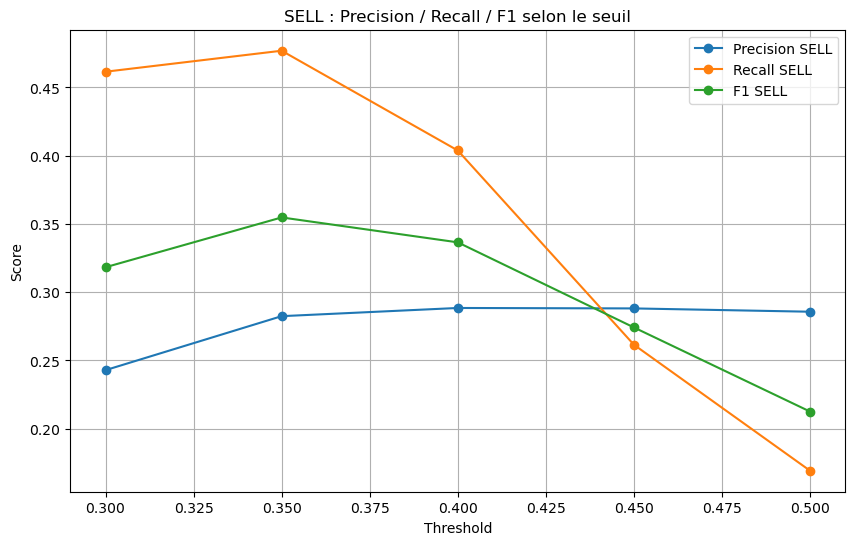

In [10]:
plt.figure(figsize=(10, 6))

plt.plot(threshold_results["threshold"], threshold_results["precision_sell"], marker="o", label="Precision SELL")
plt.plot(threshold_results["threshold"], threshold_results["recall_sell"], marker="o", label="Recall SELL")
plt.plot(threshold_results["threshold"], threshold_results["f1_sell"], marker="o", label="F1 SELL")

plt.title("SELL : Precision / Recall / F1 selon le seuil")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()



L'analyse montre que le seuil de décision influence fortement les performances du modèle.

Lorsque le seuil augmente :

- la précision reste relativement stable
- le rappel diminue fortement
- les signaux BUY et SELL deviennent plus rares

Le seuil :

### 0.35

présente le meilleur compromis entre :

- détection des opportunités
- limitation des faux signaux
- équilibre global des classes

Ce seuil sera retenu pour l'application finale.

In [11]:
import joblib

final_config = {

    "buy_threshold": 0.35,
    "sell_threshold": 0.35
}

joblib.dump(
    final_config,
    "../models/final_config.pkl"
)

print("Configuration sauvegardée")

Configuration sauvegardée
